Looking at the celing of N_shots according to Theorem 1 from original IQAE paper

In [1]:
import importlib, sys

packages = ['qiskit', 'qiskit_aer', 'qiskit_algorithms', 'numpy', 'scipy', 'joblib', 'matplotlib', 'aer', 'joblib']
print(f'Python: {sys.version}')
print()
for pkg in packages:
    try:
        mod = importlib.import_module(pkg)
        version = getattr(mod, '__version__', 'unknown')
        print(f'{pkg:20s}: {version}')
    except ImportError as e:
        print(f'{pkg:20s}: NOT INSTALLED ({e})')


Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]

qiskit              : 1.4.2
qiskit_aer          : 0.17.2
qiskit_algorithms   : 0.3.1
numpy               : 2.5.1
scipy               : 1.18.0
joblib              : 1.5.3
matplotlib          : 3.10.9
aer                 : NOT INSTALLED (No module named 'aer')
joblib              : 1.5.3


In [2]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.circuit import QuantumCircuit
from qiskit import transpile

qc = QuantumCircuit(1, 1)
qc.x(0)
qc.measure(0, 0)
    
# Build noise model
noise_model = NoiseModel()
error = depolarizing_error(0.75, 1)
noise_model.add_all_qubit_quantum_error(
    error, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# Noiseless
sim_ideal = AerSimulator()
result_ideal = sim_ideal.run(transpile(qc, sim_ideal), shots=1024).result()
print("Noiseless     :", result_ideal.get_counts())

# Noisy
sim_noisy = AerSimulator(noise_model=noise_model)
result_noisy = sim_noisy.run(transpile(qc, sim_noisy), shots=1024).result()
print("Noisy p=0.75  :", result_noisy.get_counts())

sim_check = AerSimulator()
qc_t = transpile(qc, sim_check)
print("Basis gates used:", qc_t.count_ops())

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

p_true = 0.2

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")
p_true = 0.2

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")

# ══════════════════════════════════════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════════════════════════════════════
# All standard single-qubit basis/native gates Qiskit might emit
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz',
    'u', 'u1', 'u2', 'u3', 'p'
]

# Physical ceiling for 1-qubit depolarizing_error:
#   E(rho) = (1-λ)ρ + (λ/4)(ρ + XρX + YρY + ZρZ)
#   => c_I = 1 - 3λ/4, c_X = c_Y = c_Z = λ/4
#   CP requires all c >= 0  =>  λ ∈ [0, 4/3]
#   λ = 1 is full depolarization (output = I/2); λ ∈ (1, 4/3] is
#   "over-rotation" with no interpretable "more noise" meaning here.
# For a noise-frontier sweep, the meaningful physical range is λ ∈ [0, 1].
MAX_PHYSICAL_DEPOL = 1.0

def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        p_1q = min(p_depol, MAX_PHYSICAL_DEPOL)
        error_1q = depolarizing_error(p_1q, 1)

        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(error_1q, SINGLE_QUBIT_GATES)

        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler



Noiseless     : {'1': 1024}
Noisy p=0.75  : {'1': 639, '0': 385}
Basis gates used: OrderedDict({'x': 1, 'measure': 1})
All imports OK ✅
Problem defined ✅
Problem defined ✅


In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 1 — Parameters + Helper Functions  (fixed)
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed

p_true    = 0.2
R         = 200
ALPHA     = 0.05
N_JOBS    = 18

TARGET         = 0.50
CONV_BAND = 0.02
LOCAL_HALF_WIDTH = 0.02   # accept s ∈ [0.4875, 0.5125]  ← matches agreed pseudocode
CLIFF_THRESH   = 0.05    # deviation > 0.05 from TARGET triggers cliff/drop logic
PRECISION      = 0.0001

epsilon_values = [e for e in np.linspace(0.0001, 0.1, 1000).tolist() if e <= 0.75]


# ── Wilson Score ──────────────────────────────────────────────────────────────
Z_95 = 1.96

def wilson_score(k, n, z=Z_95):
    p_hat      = k / n
    z2n        = z**2 / n
    centre     = (p_hat + z2n / 2) / (1 + z2n)
    half_width = (z * np.sqrt(p_hat * (1-p_hat) / n + z2n / 4)) / (1 + z2n)
    lower      = np.clip(centre - half_width, 0.0, 1.0)
    upper      = np.clip(centre + half_width, 0.0, 1.0)
    return float(p_hat), float(lower), float(upper), float(half_width)


# ── Ceiling N_max ──────────────────────────────────────────────────────────────
# Rounds down to prevent from overshooting the theoretical limit
def N_max_Chernoff(epsilon, alpha):
    raw = (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
          * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

def N_max_CP(epsilon, alpha):
    raw = 69 * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

In [19]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 2 — Single run + Probe
# ══════════════════════════════════════════════════════════════════════════════

def single_run(p_noise, eps, N_SHOTS):
    """One IQAE run at a fixed shot budget. Returns 1 (success) or 0 (failure)."""
    try:
        sampler = build_noisy_sampler(p_noise, N_SHOTS)
        iae     = IterativeAmplitudeEstimation(
            epsilon_target = eps,
            alpha          = ALPHA,
            sampler        = sampler,
            confint_method    = "beta" #chernoff" "beta"###################################################
        )
        result  = iae.estimate(problem)
        return 1 if abs(result.estimation_processed - p_true) <= eps else 0
    except Exception as e:
        print(f"[WARN] single_run failed: {type(e).__name__}: {e}")
        return 0


def probe(eps, p):
    """
    Run R independent IQAE runs at (eps, p) in parallel, at the ceiling
    shot budget N_max(eps, ALPHA).
    Returns (s_hat, lower_CI, upper_CI, half_width, N_SHOTS).
    """
    N_SHOTS = N_max_CP(eps, ALPHA)   # computed once per (eps) grid point, not per run

    outcomes           = Parallel(n_jobs=N_JOBS)(
        delayed(single_run)(p, eps, N_SHOTS) for _ in range(R)
    )
    k                  = sum(outcomes)
    s_hat, lo, hi, hw  = wilson_score(k, R)
    return s_hat, lo, hi, hw, N_SHOTS

In [20]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 3 — Bisection
# ══════════════════════════════════════════════════════════════════════════════

def find_boundary(eps, p_low, p_high):
    """
    Bisect over p to find p* where success rate ≈ 50% ± CONV_BAND.
    Matches the pseudocode agreed in transcript exactly.
    """
    history = []

    while (p_high - p_low) > PRECISION:

        p_mid                      = (p_low + p_high) / 2.0
        s_hat, lo, hi, hw, n_shots = probe(eps, p_mid)

        history.append({
            "p_try"       : p_mid,
            "s_hat"       : s_hat,
            "wilson_lower": lo,
            "wilson_upper": hi,
            "wilson_hw"   : hw,
            "n_shots"     : n_shots,
        })

        print(f"    ε={eps:.4f} | p={p_mid:.4f} | "
              f"s={s_hat:.3f} [{lo:.3f}, {hi:.3f}] | "
              f"N_shots={n_shots} | "
              f"window=[{p_low:.4f}, {p_high:.4f}]")

        if s_hat > TARGET + CONV_BAND:
            # ✅ Success rate too high → boundary is above p_mid → raise floor
            p_low  = p_mid

        elif s_hat < TARGET - CONV_BAND:
            # ✅ Success rate too low → boundary is below p_mid → lower ceiling
            p_high = p_mid

        else:
            # ✅ In band [0.45, 0.55] → converged
            print(f"    ✅ Converged at p={p_mid:.4f}")
            return {
                "epsilon"     : eps,
                "p_star"      : p_mid,
                "s_hat"       : s_hat,
                "wilson_lower": lo,
                "wilson_upper": hi,
                "wilson_hw"   : hw,
                "n_shots"     : n_shots,
                "converged"   : True,
                "cliff"       : False,
                "history"     : history,
                "final_p_low" : p_low,
                "final_p_high": p_high,
            }

    p_best                     = (p_low + p_high) / 2.0
    s_hat, lo, hi, hw, n_shots = probe(eps, p_best)

    print(f"    ⚠️  Precision limit at p={p_best:.4f} | s={s_hat:.3f}")
    return {
        "epsilon"     : eps,
        "p_star"      : p_best,
        "s_hat"       : s_hat,
        "wilson_lower": lo,
        "wilson_upper": hi,
        "wilson_hw"   : hw,
        "n_shots"     : n_shots,
        "converged"   : False,
        "cliff"       : False,
        "history"     : history,
        "final_p_low" : p_low,
        "final_p_high": p_high,
    }

In [21]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 4 — Outer sweep (added: early termination if p* saturates at 1.0)
# ══════════════════════════════════════════════════════════════════════════════

P_STAR_SATURATION = 0.999

def sweep_frontier(epsilon_list, local_half_width=LOCAL_HALF_WIDTH):

    results     = []
    p_star_prev = None

    for eps in epsilon_list:

        print(f"\n{'─'*60}")
        print(f"  ε = {eps:.4f}")
        print(f"{'─'*60}")

        # ── CASE 1: First epsilon ─────────────────────────────────────────────
        if p_star_prev is None:
            p_low  = 0.0
            p_high = 1.0
            cliff  = False
            print("  First ε — bisecting full range [0.0, 1.0]")

        # ── CASE 2: Subsequent epsilons ───────────────────────────────────────
        else:

            # ── Early termination ─────────────────────────────────────────────
            if p_star_prev >= P_STAR_SATURATION:
                print(f"  🛑 Early termination: p* = {p_star_prev:.4f} has "
                      f"reached the physical noise ceiling. "
                      f"All remaining ε trivially succeed. Stopping.")
                break

            print(f"  Probing at previous p* = {p_star_prev:.4f} ...")
            s_probe, lo, hi, hw, n_shots_probe = probe(eps, p_star_prev)
            print(f"  Probe: s={s_probe:.3f} [{lo:.3f}, {hi:.3f}] "
                  f"| N_shots={n_shots_probe}")

            if abs(s_probe - TARGET) <= CONV_BAND:
                p_low  = max(0.0, p_star_prev - local_half_width)
                p_high = min(1.0, p_star_prev + local_half_width)
                cliff  = False
                print(f"  Near boundary — local refinement in "
                      f"[{p_low:.4f}, {p_high:.4f}]")

            elif s_probe > TARGET + CONV_BAND:
                p_low  = p_star_prev
                p_high = 1.0
                cliff  = True
                print(f"  ⚠️  Cliff detected (s={s_probe:.3f}) — "
                      f"searching [{p_low:.4f}, {p_high:.4f}]")

            else:
                p_low  = 0.0
                p_high = p_star_prev
                cliff  = False
                print(f"  ⚠️  Boundary dropped (s={s_probe:.3f}) — "
                      f"searching [{p_low:.4f}, {p_high:.4f}]")

        # ── Bisect ────────────────────────────────────────────────────────────
        result          = find_boundary(eps, p_low, p_high)
        result["cliff"] = cliff
        result["search_window_low"]  = p_low
        result["search_window_high"] = p_high
        result["used_local_refinement"] = (
            p_star_prev is not None
            and abs(result["search_window_low"]
                    - max(0.0, p_star_prev - local_half_width)) < 1e-12
            and abs(result["search_window_high"]
                    - min(1.0, p_star_prev + local_half_width)) < 1e-12
            if p_star_prev is not None else False
        )

        results.append(result)
        p_star_prev = result["p_star"]

        status = "✅ converged" if result["converged"] else "⚠️  precision limit"
        print(f"\n  {status} | p* = {result['p_star']:.4f} | "
              f"s = {result['s_hat']:.3f} | N_shots = {result['n_shots']}")

        # ── Post-step saturation check ─────────────────────────────────────
        # Checked after append so the saturated point is still saved
        if result["p_star"] >= P_STAR_SATURATION:
            print(f"\n  🛑 p* = {result['p_star']:.4f} reached the physical "
                  f"noise ceiling. Terminating after this point.")
            break

    return results

In [22]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 5 — Full run
# ══════════════════════════════════════════════════════════════════════════════

frontier_results = sweep_frontier(epsilon_values)

print(f"\n{'═'*60}")
print(f"  ✅ Frontier sweep complete — {len(frontier_results)} points")
print(f"{'═'*60}")

for r in frontier_results:
    cliff_tag = " ⚠️  CLIFF" if r["cliff"] else ""
    conv_tag  = "✅" if r["converged"] else "⚠️ "
    print(f"  {conv_tag} ε={r['epsilon']:.5f} | "
          f"p*={r['p_star']:.4f} | "
          f"s={r['s_hat']:.3f} | "
          f"N={r['n_shots']}{cliff_tag}")


────────────────────────────────────────────────────────────
  ε = 0.0001
────────────────────────────────────────────────────────────
  First ε — bisecting full range [0.0, 1.0]
    ε=0.0001 | p=0.5000 | s=0.000 [0.000, 0.143] | N_shots=431 | window=[0.0000, 1.0000]
    ε=0.0001 | p=0.2500 | s=0.045 [0.000, 0.190] | N_shots=431 | window=[0.0000, 0.5000]
    ε=0.0001 | p=0.1250 | s=0.515 [0.365, 0.664] | N_shots=431 | window=[0.0000, 0.2500]
    ✅ Converged at p=0.1250

  ✅ converged | p* = 0.1250 | s = 0.515 | N_shots = 431

────────────────────────────────────────────────────────────
  ε = 0.0002
────────────────────────────────────────────────────────────
  Probing at previous p* = 0.1250 ...
  Probe: s=0.450 [0.301, 0.600] | N_shots=425
  ⚠️  Boundary dropped (s=0.450) — searching [0.0000, 0.1250]
    ε=0.0002 | p=0.0625 | s=0.895 [0.748, 1.000] | N_shots=425 | window=[0.0000, 0.1250]
    ε=0.0002 | p=0.0938 | s=0.690 [0.539, 0.834] | N_shots=425 | window=[0.0625, 0.1250]
    ε=0.

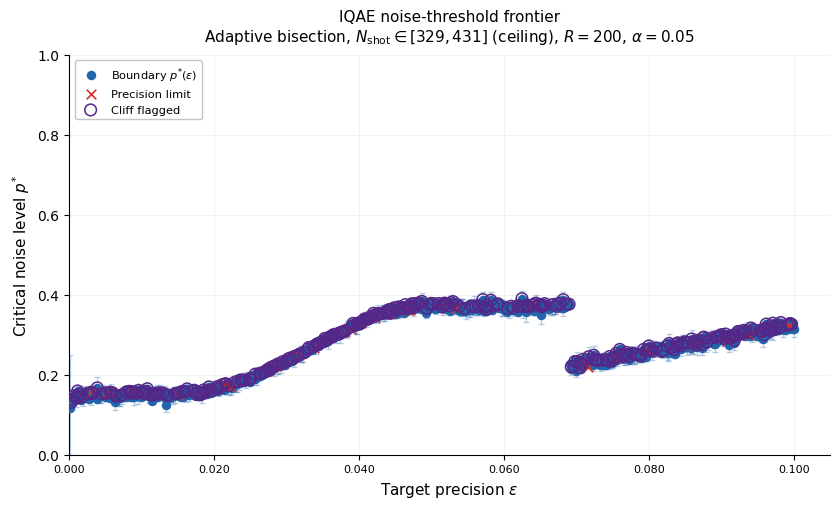

In [23]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 6 — Plot (corrected error bars from final bisection bracket)
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# -----------------------------------------------------------------------------
# IMPORTANT:
# For the most defensible p* error bars, store the final bracket endpoints in
# find_boundary(...) when returning each result dict:
#
#   "final_p_low": p_low,
#   "final_p_high": p_high,
#
# If those keys are not present, this cell falls back to ±PRECISION/2.
# -----------------------------------------------------------------------------


def estimate_p_star_uncertainty(result, precision=PRECISION):
    """
    Return asymmetric uncertainty on p* in p-units.

    Preferred source:
      - final bisection bracket [final_p_low, final_p_high]

    Fallback:
      - symmetric ± precision/2 if the bracket was not stored

    This avoids mixing success-rate uncertainty units with p-units.
    """
    p_star = float(result["p_star"])

    if "final_p_low" in result and "final_p_high" in result:
        p_low = float(result["final_p_low"])
        p_high = float(result["final_p_high"])

        lower_err = max(0.0, p_star - p_low)
        upper_err = max(0.0, p_high - p_star)
    else:
        err = precision / 2.0
        lower_err = err
        upper_err = err

    # Hard cap to physical range [0, 1]
    lower_err = min(lower_err, p_star)
    upper_err = min(upper_err, 1.0 - p_star)

    return float(lower_err), float(upper_err)


# ── Build plotting arrays ─────────────────────────────────────────────────────
eps_vals    = [r["epsilon"] for r in frontier_results]
p_star_vals = [r["p_star"] for r in frontier_results]
conv_mask   = [r["converged"] for r in frontier_results]
cliff_mask  = [r.get("cliff", False) for r in frontier_results]
n_shots_vals = [r.get("n_shots") for r in frontier_results if r.get("n_shots") is not None]

lower_errs, upper_errs = [], []
for r in frontier_results:
    lo, hi = estimate_p_star_uncertainty(r)
    lower_errs.append(lo)
    upper_errs.append(hi)

yerr = np.array([lower_errs, upper_errs])  # shape (2, N) for asymmetric bars

# ── Predicted cliff locations  ε_cliff^(n) = π / (4 · r_min^n) ──────────────
# Keep this only if r_min is actually the one used in simulation.
r_min = 2
cliffs = {n: np.pi / (4 * r_min**n) for n in range(3, 7)}

# ── Figure setup ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8.5, 5.2))

# ── Error bars on p* ──────────────────────────────────────────────────────────
ax.errorbar(
    eps_vals,
    p_star_vals,
    yerr=yerr,
    fmt='none',
    ecolor='#2166ac',
    alpha=0.30,
    capsize=2.5,
    elinewidth=0.9,
    label='_nolegend_'
)

# ── Converged points ──────────────────────────────────────────────────────────
conv_eps = [e for e, cv in zip(eps_vals, conv_mask) if cv]
conv_p   = [p for p, cv in zip(p_star_vals, conv_mask) if cv]
ax.scatter(
    conv_eps,
    conv_p,
    color='#2166ac',
    s=34,
    zorder=3,
    label=r'Boundary $p^{*}(\varepsilon)$'
)

# ── Not-converged points ──────────────────────────────────────────────────────
nc_eps = [e for e, cv in zip(eps_vals, conv_mask) if not cv]
nc_p   = [p for p, cv in zip(p_star_vals, conv_mask) if not cv]
if nc_eps:
    ax.scatter(
        nc_eps,
        nc_p,
        color='#d73027',
        marker='x',
        s=48,
        linewidths=1.2,
        zorder=4,
        label='Precision limit'
    )

# ── Optional overlay: cliff-flagged points from sweep ────────────────────────
cliff_eps = [e for e, cf in zip(eps_vals, cliff_mask) if cf]
cliff_p   = [p for p, cf in zip(p_star_vals, cliff_mask) if cf]
if cliff_eps:
    ax.scatter(
        cliff_eps,
        cliff_p,
        facecolors='none',
        edgecolors='#542788',
        s=70,
        linewidths=1.1,
        zorder=5,
        label='Cliff flagged'
    )



# ── Axes & styling ────────────────────────────────────────────────────────────
ax.set_xscale('linear')
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
ax.tick_params(axis='x', labelsize=8)

ax.set_xlabel(r'Target precision $\varepsilon$', fontsize=11)
ax.set_ylabel(r'Critical noise level $p^{*}$', fontsize=11)

# N_shots now varies per epsilon (ceiling mode: N_max(eps, ALPHA)),
# so show the range rather than a single fixed value.
if n_shots_vals:
    n_shots_label = rf'$N_{{\mathrm{{shot}}}} \in [{min(n_shots_vals)}, {max(n_shots_vals)}]$ (ceiling)'
else:
    n_shots_label = rf'$N_{{\mathrm{{shot}}}}$ = <UNSET>'

ax.set_title(
    r'IQAE noise-threshold frontier' + '\n' +
    rf'Adaptive bisection, {n_shots_label}, $R={R}$, $\alpha={ALPHA}$',
    fontsize=11,
    pad=10
)

ax.legend(
    fontsize=8.2,
    framealpha=0.92,
    edgecolor='0.75',
    loc='upper left',
    ncol=1
)
ax.grid(True, which='both', alpha=0.22, linewidth=0.5)
ax.set_xlim(left=0.0, right=max(eps_vals) * 1.05)
ax.set_ylim(0.0, 1)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# Recommended patch to find_boundary(...): add these keys to every return dict
# so the plot can use the real final bracket instead of ±PRECISION/2 fallback.
#
#   "final_p_low": p_low,
#   "final_p_high": p_high,
# -----------------------------------------------------------------------------

In [24]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 7 — Export compact frontier data points + run parameters to a TXT file
# ══════════════════════════════════════════════════════════════════════════════

from datetime import datetime
import os
import math


def _safe_get(name, default="<UNSET>"):
    return globals().get(name, default)


def _format_scalar(x):
    try:
        import numpy as np
        if isinstance(x, (np.floating, np.integer)):
            return x.item()
    except Exception:
        pass
    return x


def _format_epsilon_values_as_linspace(vals):
    """Return a compact np.linspace(...) string if the grid is evenly spaced."""
    try:
        vals = list(vals)
        if len(vals) >= 2:
            start = float(vals[0])
            stop = float(vals[-1])
            num = len(vals)
            step = (stop - start) / (num - 1)

            evenly_spaced = all(
                math.isclose(float(vals[i + 1]) - float(vals[i]), step, rel_tol=1e-9, abs_tol=1e-12)
                for i in range(num - 1)
            )

            if evenly_spaced:
                return f"np.linspace({start:.6f}, {stop:.6f}, {num}).tolist()"
    except Exception:
        pass

    return repr(vals)


def export_frontier_points_txt(
    frontier_results,
    filename="iqae_frontier_points_export.txt",
    extra_notes=None,
):
    """
    Export only the compact frontier data points plus run parameters to a TXT file.

    The file contains:
      1. timestamp
      2. top-level experiment parameters
      3. compact frontier data points only (now including n_shots per point,
         since shots are computed per-epsilon via N_max(eps, ALPHA) rather
         than fixed for the whole run)
    """

    epsilon_values = _safe_get("epsilon_values")

    params = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "p_true": _format_scalar(_safe_get("p_true")),
        "R": _format_scalar(_safe_get("R")),
        "ALPHA": _format_scalar(_safe_get("ALPHA")),
        "N_JOBS": _format_scalar(_safe_get("N_JOBS")),
        "TARGET": _format_scalar(_safe_get("TARGET")),
        "CONV_BAND": _format_scalar(_safe_get("CONV_BAND")),
        "CLIFF_THRESH": _format_scalar(_safe_get("CLIFF_THRESH")),
        "PRECISION": _format_scalar(_safe_get("PRECISION")),
        "epsilon_values": _format_epsilon_values_as_linspace(epsilon_values)
            if epsilon_values != "<UNSET>" else "<UNSET>",
        "SINGLE_QUBIT_GATES": _format_scalar(_safe_get("SINGLE_QUBIT_GATES")),
        "N_shots_mode": "ceiling (N_max(eps, ALPHA), varies per epsilon — see n_shots column below)",
    }

    optional_names = [
        "r_min",
        "Z_95",
        "backend_name",
        "noise_model_name",
        "sampler_type",
    ]
    for name in optional_names:
        if name in globals():
            params[name] = _format_scalar(globals()[name])

    lines = []
    lines.append("=" * 80)
    lines.append("IQAE FRONTIER DATA POINTS EXPORT")
    lines.append("=" * 80)
    lines.append("")

    lines.append("[RUN PARAMETERS]")
    for k, v in params.items():
        lines.append(f"{k}: {v}")
    if extra_notes is not None:
        lines.append(f"extra_notes: {extra_notes}")
    lines.append("")

    lines.append("[FRONTIER DATA POINTS]")
    header = "epsilon | p_star | s_hat | n_shots | converged | cliff"
    lines.append(header)
    lines.append("-" * len(header))

    for r in frontier_results:
        eps = float(r.get("epsilon", float("nan")))
        p_star = float(r.get("p_star", float("nan")))
        s_hat = float(r.get("s_hat", float("nan")))
        n_shots = r.get("n_shots", "<UNSET>")
        converged = r.get("converged", False)
        cliff = r.get("cliff", False)

        lines.append(
            f"{eps:.6f} | {p_star:.6f} | {s_hat:.6f} | {n_shots} | {converged} | {cliff}"
        )

    lines.append("")

    with open(filename, "w", encoding="utf-8") as f:
        f.write("\n".join(lines))

    print(f"✅ Exported compact frontier data points to: {os.path.abspath(filename)}")
    return os.path.abspath(filename)


# ── Example usage ────────────────────────────────────────────────────────────
export_path = export_frontier_points_txt(
    frontier_results,
    filename="data1.txt",
    extra_notes="Compact export: parameters at top, frontier data points only."
)
print(export_path)

✅ Exported compact frontier data points to: c:\Summer-Research-2026\Ceiling analysis\data1.txt
c:\Summer-Research-2026\Ceiling analysis\data1.txt
